<a href="https://colab.research.google.com/github/AbhayKHulasad/DAV-LAB/blob/main/Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [2]:
data = {
    'Student': ['A','B','C','D','E','F','G','H','I','J',
                'K','L','M','N','O','P','Q','R','S','T'],

    'Marks': [45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
              61, 57, 63, 56, 54, 51, 49, 95, 100, 5]
}

df = pd.DataFrame(data)

print(df)


   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


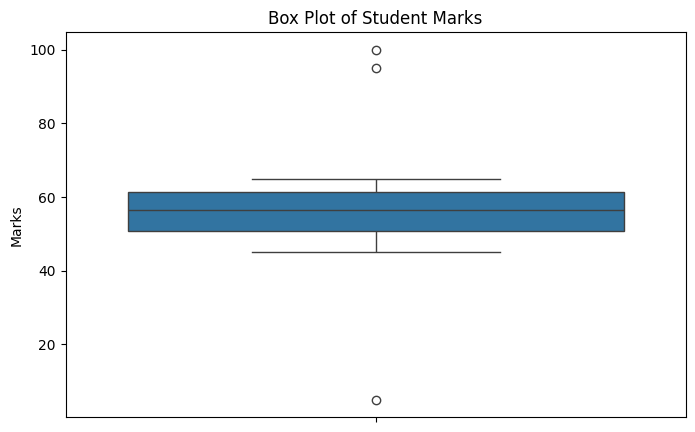

In [3]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")

plt.show()


In [4]:
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)



Q1 = 50.75
Q3 = 61.25


In [5]:
IQR = Q3 - Q1

print("IQR =", IQR)


IQR = 10.5


In [6]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)


Lower Limit = 35.0
Upper Limit = 77.0


In [7]:
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr)


Outliers detected using IQR:
   Student  Marks
17       R     95
18       S    100
19       T      5


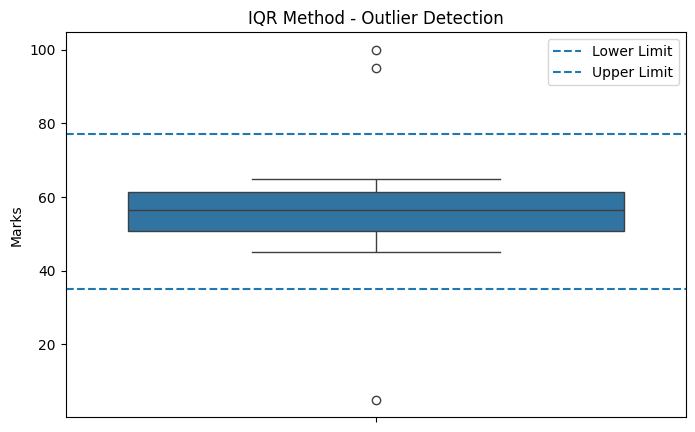

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()


In [9]:
df['Marks_IQR_Capped'] = df['Marks'].clip(lower=lower_limit,upper=upper_limit)

print(df[['Marks', 'Marks_IQR_Capped']])


    Marks  Marks_IQR_Capped
0      45                45
1      50                50
2      52                52
3      48                48
4      55                55
5      60                60
6      58                58
7      62                62
8      65                65
9      59                59
10     61                61
11     57                57
12     63                63
13     56                56
14     54                54
15     51                51
16     49                49
17     95                77
18    100                77
19      5                35


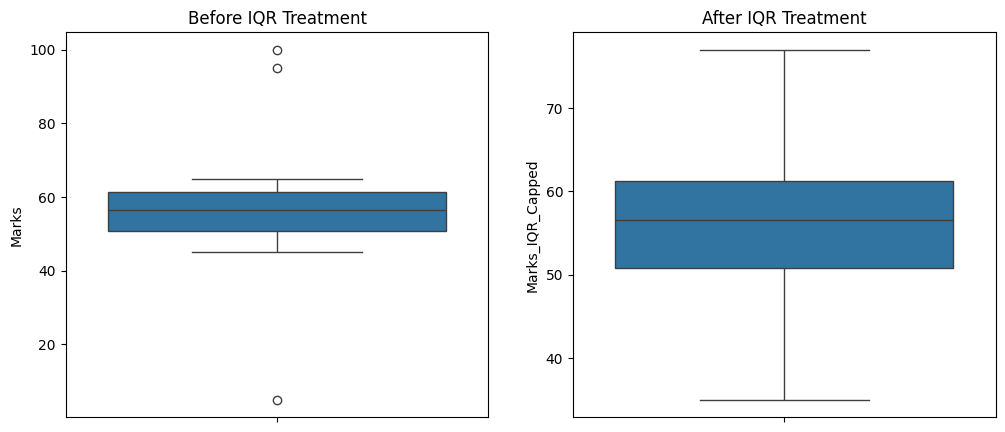

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()


In [11]:
df['Z_score'] = stats.zscore(df['Marks'])

print(df[['Marks', 'Z_score']])


    Marks   Z_score
0      45 -0.676200
1      50 -0.400200
2      52 -0.289800
3      48 -0.510600
4      55 -0.124200
5      60  0.151800
6      58  0.041400
7      62  0.262200
8      65  0.427800
9      59  0.096600
10     61  0.207000
11     57 -0.013800
12     63  0.317400
13     56 -0.069000
14     54 -0.179400
15     51 -0.345000
16     49 -0.455400
17     95  2.083800
18    100  2.359799
19      5 -2.884199


In [12]:
z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)


Outliers detected using Z-score:
Empty DataFrame
Columns: [Student, Marks, Marks_IQR_Capped, Z_score]
Index: []


In [13]:
df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['Marks', 'Z_score', 'Z_Outlier']])


    Marks   Z_score  Z_Outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800      False
18    100  2.359799      False
19      5 -2.884199      False


In [14]:
mean = df['Marks'].mean()
std = df['Marks'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)


Lower Z-score limit = 1.4902946847626737
Upper Z-score limit = 113.00970531523733


In [16]:

df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['Marks', 'Marks_Z_Capped']])


    Marks  Marks_Z_Capped
0      45              45
1      50              50
2      52              52
3      48              48
4      55              55
5      60              60
6      58              58
7      62              62
8      65              65
9      59              59
10     61              61
11     57              57
12     63              63
13     56              56
14     54              54
15     51              51
16     49              49
17     95              95
18    100             100
19      5               5


    Marks  Marks_IQR_Capped  Marks_Z_Capped
0      45                45              45
1      50                50              50
2      52                52              52
3      48                48              48
4      55                55              55
5      60                60              60
6      58                58              58
7      62                62              62
8      65                65              65
9      59                59              59
10     61                61              61
11     57                57              57
12     63                63              63
13     56                56              56
14     54                54              54
15     51                51              51
16     49                49              49
17     95                77              95
18    100                77             100
19      5                35               5


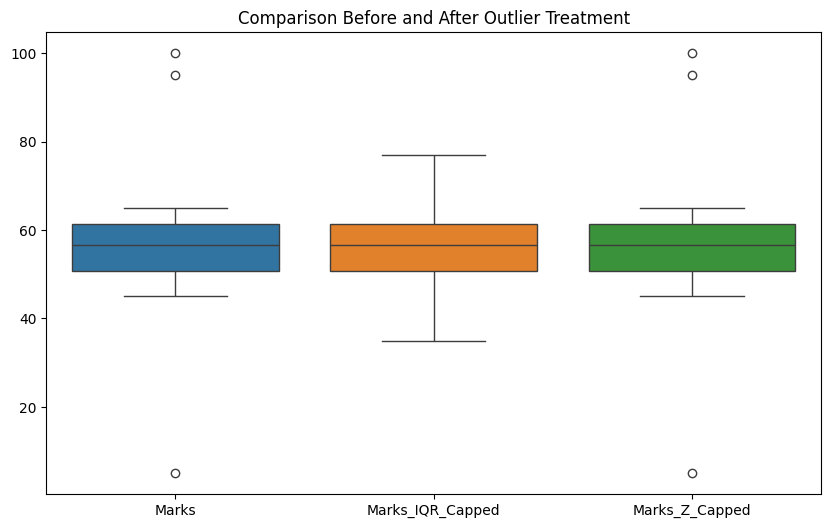

In [17]:
print(df[['Marks',
          'Marks_IQR_Capped',
          'Marks_Z_Capped']])

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [20]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('test.csv')
print(df)

Saving test.csv to test.csv
        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0     1461          20       RH         80.0    11622   Pave   NaN      Reg   
1     1462          20       RL         81.0    14267   Pave   NaN      IR1   
2     1463          60       RL         74.0    13830   Pave   NaN      IR1   
3     1464          60       RL         78.0     9978   Pave   NaN      IR1   
4     1465         120       RL         43.0     5005   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1454  2915         160       RM         21.0     1936   Pave   NaN      Reg   
1455  2916         160       RM         21.0     1894   Pave   NaN      Reg   
1456  2917          20       RL        160.0    20000   Pave   NaN      Reg   
1457  2918          85       RL         62.0    10441   Pave   NaN      Reg   
1458  2919          60       RL         74.0     9627   Pave   NaN      Reg   

     LandContour Utilit

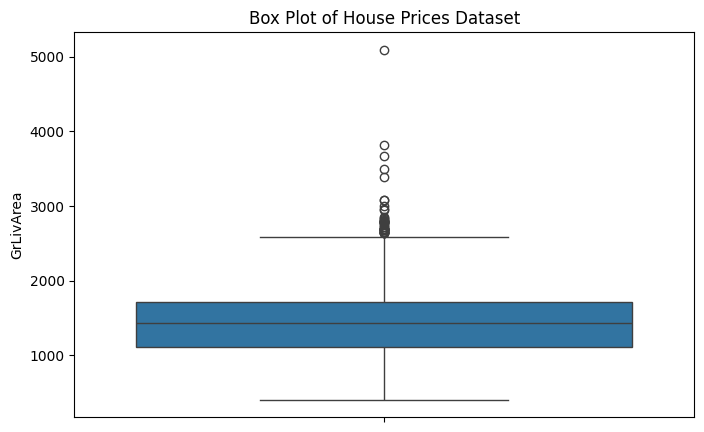

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['GrLivArea'])

plt.title("Box Plot of House Prices Dataset")
plt.ylabel("GrLivArea")

plt.show()

In [22]:
Q1 = df['GrLivArea'].quantile(0.25)
Q3 = df['GrLivArea'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

Q1 = 1117.5
Q3 = 1721.0


In [23]:
IQR = Q3 - Q1

print("IQR =", IQR)

IQR = 603.5


In [24]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

Lower Limit = 212.25
Upper Limit = 2626.25


In [25]:
outliers_iqr = df[
    (df['GrLivArea'] < lower_limit) |
    (df['GrLivArea'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr)

Outliers detected using IQR:
        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
19    1480          20       RL        110.0    14300   Pave   NaN      Reg   
133   1594          90       RH         60.0     7200   Pave  Pave      Reg   
179   1640          60       RL          NaN    12388   Pave   NaN      IR1   
200   1661          60       RL        110.0    14257   Pave   NaN      Reg   
201   1662          60       RL         95.0    12350   Pave   NaN      Reg   
203   1664          20       RL        105.0    13693   Pave   NaN      Reg   
237   1698          60       RL        106.0    12720   Pave   NaN      Reg   
278   1739         160       FV         32.0     2880   Pave  Pave      Reg   
287   1748          60       RL         80.0    10400   Pave   NaN      Reg   
401   1862          90       RL          NaN    11855   Pave   NaN      Reg   
402   1863          90       RL          NaN     7939   Pave   NaN      Reg   
403   1864          90 

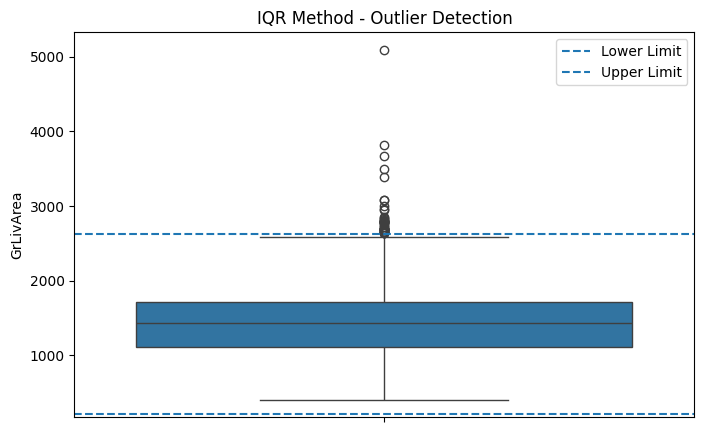

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['GrLivArea'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()

In [27]:
df['GrLivArea_IQR_Capped'] = df['GrLivArea'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['GrLivArea', 'GrLivArea_IQR_Capped']])

      GrLivArea  GrLivArea_IQR_Capped
0           896                 896.0
1          1329                1329.0
2          1629                1629.0
3          1604                1604.0
4          1280                1280.0
...         ...                   ...
1454       1092                1092.0
1455       1092                1092.0
1456       1224                1224.0
1457        970                 970.0
1458       2000                2000.0

[1459 rows x 2 columns]


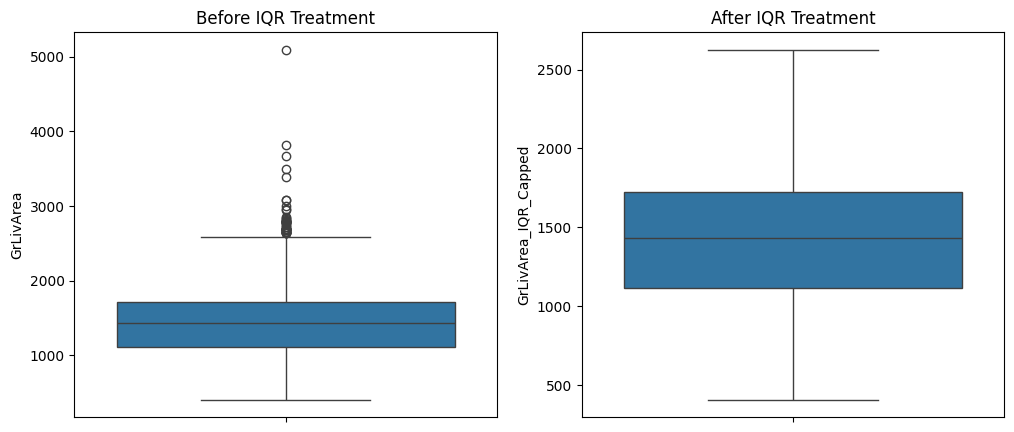

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['GrLivArea'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['GrLivArea_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()

In [29]:
df['Z_score'] = stats.zscore(df['GrLivArea'])

print(df[['GrLivArea', 'Z_score']])

      GrLivArea   Z_score
0           896 -1.215588
1          1329 -0.323539
2          1629  0.294508
3          1604  0.243004
4          1280 -0.424487
...         ...       ...
1454       1092 -0.811797
1455       1092 -0.811797
1456       1224 -0.539856
1457        970 -1.063136
1458       2000  1.058827

[1459 rows x 2 columns]


In [30]:
z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)

df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['GrLivArea', 'Z_score', 'Z_Outlier']])

Outliers detected using Z-score:
        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
278   1739         160       FV         32.0     2880   Pave  Pave      Reg   
579   2040          60       RL          NaN    24572   Pave   NaN      IR1   
728   2189          20       RL        123.0    47007   Pave   NaN      IR1   
838   2299          60       RL         99.0    13069   Pave   NaN      IR1   
871   2332          60       RL         89.0    10557   Pave   NaN      IR1   
964   2425          70       RL        113.0    21281   Pave   NaN      Reg   
1089  2550          20       RL        128.0    39290   Pave   NaN      IR1   
1168  2629          60       RL         60.0    18062   Pave   NaN      IR1   
1222  2683          60       RL        114.0    17242   Pave   NaN      IR1   
1362  2823          75       RL         60.0    19800   Pave   NaN      Reg   

     LandContour Utilities  ... PoolQC Fence MiscFeature MiscVal MoSold  \
278          Lvl    Al

In [31]:
mean = df['GrLivArea'].mean()
std = df['GrLivArea'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

Lower Z-score limit = 29.347625904531014
Upper Z-score limit = 2942.7442178240503


In [32]:
df['GrLivArea_Z_Capped'] = df['GrLivArea'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['GrLivArea', 'GrLivArea_Z_Capped']])

      GrLivArea  GrLivArea_Z_Capped
0           896               896.0
1          1329              1329.0
2          1629              1629.0
3          1604              1604.0
4          1280              1280.0
...         ...                 ...
1454       1092              1092.0
1455       1092              1092.0
1456       1224              1224.0
1457        970               970.0
1458       2000              2000.0

[1459 rows x 2 columns]


In [33]:
print(df[
    [
        'GrLivArea',
        'GrLivArea_IQR_Capped',
        'GrLivArea_Z_Capped'
    ]
])

      GrLivArea  GrLivArea_IQR_Capped  GrLivArea_Z_Capped
0           896                 896.0               896.0
1          1329                1329.0              1329.0
2          1629                1629.0              1629.0
3          1604                1604.0              1604.0
4          1280                1280.0              1280.0
...         ...                   ...                 ...
1454       1092                1092.0              1092.0
1455       1092                1092.0              1092.0
1456       1224                1224.0              1224.0
1457        970                 970.0               970.0
1458       2000                2000.0              2000.0

[1459 rows x 3 columns]


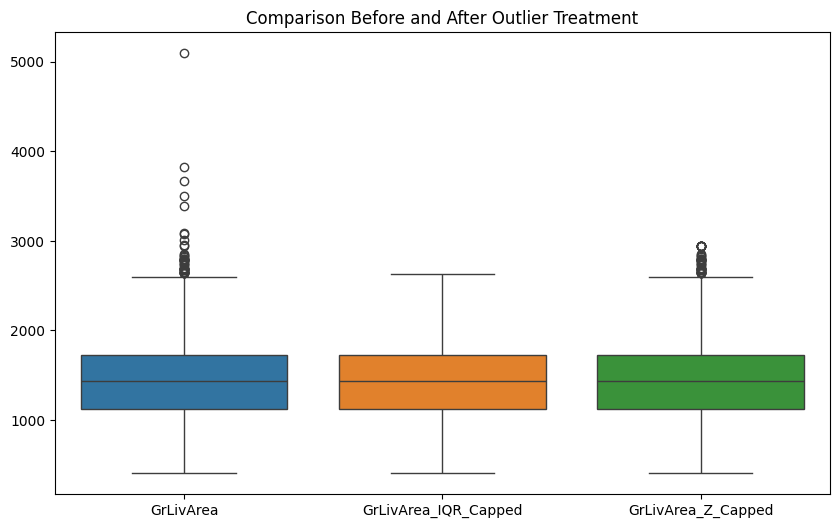

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    [
        'GrLivArea',
        'GrLivArea_IQR_Capped',
        'GrLivArea_Z_Capped'
    ]
])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()